# 5. lecke – King County lakásárak becslése

A házfeladat célja az eladási ár időrendi, ismétlődő ingatlanoktól megtisztított validációja, majd egyetlen, előre félretett időszakos tesztértékelése.


## 1. Kérdés és célváltozó

A becsült szám az ingatlan **eladási ára USD-ben**. Hitelezési értékbecslésnél a túlbecslés lehet drágább, mert a fedezet tényleges értékénél nagyobb hitelhez vezethet; ezért ezt a kockázatot külön, a jósolt és tényleges összeg arányával és a nagy hibákat erősen büntető RMSE-vel is figyelem. Előre rögzített fő mutatóm a dollárösszegre számolt **WAPE** (összes abszolút hiba / tényleges árösszeg), mellette az RMSE, MAE, RMSLE, R² és a jósolt/tényleges összeg aránya; az MAE tipikus dollárhibát, az RMSLE relatív eltérést, az R² pedig kiegészítő illeszkedést mutat, egyik sem helyettesíti a WAPE-t. Ezek a mutatók szimmetrikusak, ezért az üzleti aszimmetriát az összegarány és a nagy hibák külön bemutatása jelzi, nem utólagos teszthangolás.


## 2. Feltáró adatelemzés

Először az eloszlásokat, a helyi árkülönbségeket, a havi mediánt és a lakóterület kapcsolatát nézem meg; ezek leíró ábrák, nem szolgálnak modellválasztásra. A célár erősen jobbra ferde, ezért a modellek a `log1p(ár)` célon tanulnak, a becsléseket `expm1`-gyel dollárra alakítom vissza, és az ebből adódó összegarány-torzítást külön mérem.


In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.dpi"] = 80
plt.rcParams["axes.grid"] = True
SEED = 42
PROPERTY_KEY = ["lat", "long", "sqft_living", "sqft_lot", "yr_built", "zipcode"]
HOUSE_COLUMNS = [
    "date", "price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors",
    "waterfront", "view", "condition", "grade", "sqft_above", "sqft_basement",
    "yr_built", "yr_renovated", "zipcode", "lat", "long", "sqft_living15", "sqft_lot15",
]
try:
    from xgboost import XGBRegressor
    HAS_XGBOOST = True
except ImportError:
    XGBRegressor = None
    HAS_XGBOOST = False


def metrics(actual, predicted):
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    return {
        "WAPE": np.abs(actual - predicted).sum() / np.abs(actual).sum(),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSLE": mean_squared_log_error(np.maximum(actual, 0), np.maximum(predicted, 0)) ** 0.5,
        "R²": r2_score(actual, predicted),
        "Jósolt/tényleges összeg": predicted.sum() / actual.sum(),
    }


def estimator(name, seed):
    if name == "Ridge":
        return Ridge(alpha=10.0)
    if name == "Döntési fa":
        return DecisionTreeRegressor(max_depth=14, min_samples_leaf=15, random_state=seed)
    if name == "Random Forest":
        return RandomForestRegressor(n_estimators=200, min_samples_leaf=2, max_features=0.5,
                                     n_jobs=-1, random_state=seed)
    if HAS_XGBOOST:
        return XGBRegressor(n_estimators=500, max_depth=4, max_bin=64, learning_rate=0.04, subsample=0.85,
                            colsample_bytree=0.85, reg_lambda=5.0, objective="reg:squarederror",
                            tree_method="hist", n_jobs=4, random_state=seed, verbosity=0)
    return HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=31,
                                         l2_regularization=3.0, random_state=seed)


def predict(name, X_train, y_train, X_valid, seed=SEED):
    y_train = np.asarray(y_train, dtype=float)
    if name == "Átlag":
        return np.full(len(X_valid), y_train.mean())
    if name == "ZIP-medián":
        medians = pd.DataFrame({"zipcode": X_train.zipcode.values, "price": y_train}).groupby("zipcode").price.median()
        return X_valid.zipcode.map(medians).fillna(np.median(y_train)).to_numpy()
    numeric = [column for column in X_train if column != "zipcode"]
    transform = StandardScaler() if name == "Ridge" else "passthrough"
    prep = ColumnTransformer(
        [("numeric", transform, numeric),
         ("zipcode", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["zipcode"])],
        remainder="drop", sparse_threshold=0.0,
    )
    pipe = Pipeline([("preprocess", prep), ("model", estimator(name, seed))])
    pipe.fit(X_train, np.log1p(y_train))
    return np.maximum(np.expm1(pipe.predict(X_valid)), 0.0)


In [2]:
try:
    raw = fetch_openml(data_id=42092, as_frame=True).frame.copy()
    data_source = "OpenML (42092)"
except Exception as openml_error:
    local_path = Path("kc_house_data.csv")
    if not local_path.is_file():
        local_path = Path("lesson 5") / "kc_house_data.csv"
    if not local_path.is_file():
        raise FileNotFoundError("Az OpenML nem érhető el, és a kc_house_data.csv sem található.") from openml_error
    csv_frame = pd.read_csv(local_path)
    missing_columns = set(HOUSE_COLUMNS) - set(csv_frame.columns)
    if missing_columns:
        raise ValueError(f"Hiányzó adatmezők a CSV-ben: {sorted(missing_columns)}")
    raw = csv_frame.loc[:, HOUSE_COLUMNS].copy()
    data_source = str(local_path)

missing_columns = set(HOUSE_COLUMNS) - set(raw.columns)
if missing_columns:
    raise ValueError(f"Hiányzó adatmezők: {sorted(missing_columns)}")
raw = raw.loc[:, HOUSE_COLUMNS].copy()
raw["date"] = pd.to_datetime(raw["date"].astype(str), format="%Y%m%dT%H%M%S", errors="raise")
raw["zipcode"] = raw["zipcode"].astype(str).str.zfill(5)
print(f"Forrás: {data_source}; méret: {len(raw):,} sor × {len(raw.columns)} oszlop.")
print(f"Hiányzó érték: {int(raw.isna().sum().sum())}; dátum: {raw.date.min():%Y-%m-%d} – {raw.date.max():%Y-%m-%d}.")
print(f"Átlagár ${raw.price.mean():,.0f}; medián ${raw.price.median():,.0f}; maximum ${raw.price.max():,.0f}; $1M fölött {(raw.price > 1_000_000).mean():.1%}.")
print(f"Irányítószám: {raw.zipcode.nunique()}; bedrooms maximum: {raw.bedrooms.max()}; yr_renovated=0 arány: {(raw.yr_renovated == 0).mean():.1%}.")
assert raw.shape == (21613, 20) and raw.isna().sum().sum() == 0


Forrás: OpenML (42092); méret: 21,613 sor × 20 oszlop.
Hiányzó érték: 0; dátum: 2014-05-02 – 2015-05-27.
Átlagár $540,088; medián $450,000; maximum $7,700,000; $1M fölött 6.8%.
Irányítószám: 70; bedrooms maximum: 33; yr_renovated=0 arány: 95.8%.


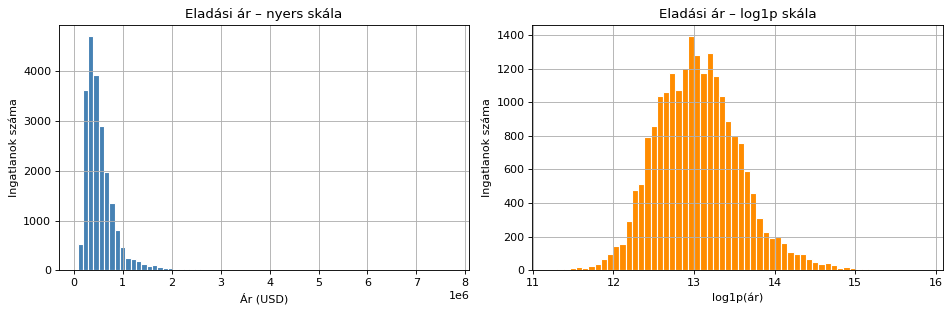

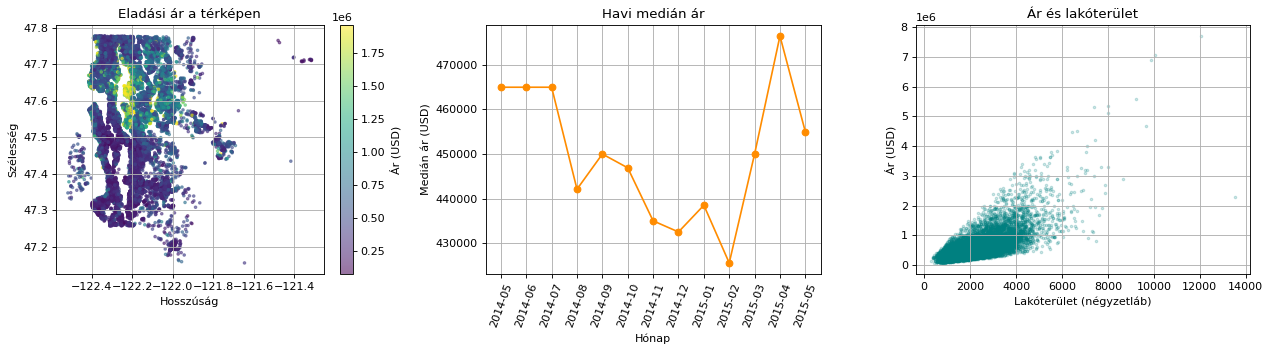

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw.price, bins=70, color="steelblue", edgecolor="white")
axes[0].set(title="Eladási ár – nyers skála", xlabel="Ár (USD)", ylabel="Ingatlanok száma")
axes[1].hist(np.log1p(raw.price), bins=60, color="darkorange", edgecolor="white")
axes[1].set(title="Eladási ár – log1p skála", xlabel="log1p(ár)", ylabel="Ingatlanok száma")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
scatter = axes[0].scatter(raw.long, raw.lat, c=raw.price, s=5, alpha=0.55, cmap="viridis",
                          vmax=raw.price.quantile(0.99))
axes[0].set(title="Eladási ár a térképen", xlabel="Hosszúság", ylabel="Szélesség")
fig.colorbar(scatter, ax=axes[0], label="Ár (USD)")
monthly = raw.assign(month=raw.date.dt.to_period("M")).groupby("month").price.median()
axes[1].plot(monthly.index.astype(str), monthly.values, marker="o", color="darkorange")
axes[1].tick_params(axis="x", rotation=70)
axes[1].set(title="Havi medián ár", xlabel="Hónap", ylabel="Medián ár (USD)")
axes[2].scatter(raw.sqft_living, raw.price, s=5, alpha=0.2, color="teal")
axes[2].set(title="Ár és lakóterület", xlabel="Lakóterület (négyzetláb)", ylabel="Ár (USD)")
plt.tight_layout()
plt.show()


## 3. Tisztítás és előkészítés

Az öt, legalább 10 hálószobás sort – köztük a 33 hálószobás ingatlant – kihagyom, mert valószínű adathibák; az árakat nem vágom le, mert a drága eladások a célpopuláció részei. A `yr_renovated = 0` azt jelenti, hogy nem volt felújítás, ezért jelzőt és az utolsó munka óta eltelt időt képzek, nem kezelem a nullát tényleges évként. Az irányítószám kategória, az ismétlődéseket pedig a hat, célváltozótól független mezőből képzett közelítő ingatlankulcs azonosítja.


In [4]:
codes, _ = pd.factorize(pd.MultiIndex.from_frame(raw[PROPERTY_KEY]))
raw["prop_id"] = codes
counts = pd.Series(codes).value_counts()
print(f"Azonos kulcsú ismétlődő eladások: {int(counts[counts > 1].sum())} sor, {int((counts > 1).sum())} ingatlan.")
cleaned = raw.loc[raw.bedrooms < 10].copy()
cleaned["renovated"] = (cleaned.yr_renovated > 0).astype(int)
last_work = cleaned.yr_renovated.where(cleaned.renovated.eq(1), cleaned.yr_built)
cleaned["years_since_work"] = cleaned.date.dt.year - last_work
cleaned["house_age"] = cleaned.date.dt.year - cleaned.yr_built
cleaned = cleaned.sort_values("date", kind="stable").reset_index(drop=True)
print(f"Kihagyott ≥10 hálószobás sor: {len(raw) - len(cleaned)}; megtartott: {len(cleaned):,}; árkivágás: 0 sor.")
assert int((raw.bedrooms >= 10).sum()) == 5


Azonos kulcsú ismétlődő eladások: 392 sor, 195 ingatlan.
Kihagyott ≥10 hálószobás sor: 5; megtartott: 21,608; árkivágás: 0 sor.


## 4. Felosztás – előbb a tanító- és tesztrész

A jövőbeli eladásokat becsüljük, ezért a teszt a dátumrend utolsó 20%-a, nem véletlen minta; véletlen vágás közeli vagy azonos házhoz tartozó eladásokat is a tanítóba juttatna. A 13 hónap miatt a teszt egyetlen késői szezon, várhatóan 2015-03-10 körüli kezdettel, a faalapú modellek pedig nem tudnak időn túl extrapolálni. A fejlesztési részen három kiterjedő időrendi ablakot használok; ha validációs vagy tesztblokkban egy ingatlan megjelenik, minden korábbi tanítóeladását eltávolítom.


In [5]:
test_start = pd.Timestamp(cleaned.date.iloc[int(0.80 * len(cleaned))])
dev = cleaned.loc[cleaned.date < test_start].copy()
test = cleaned.loc[cleaned.date >= test_start].copy()
final_train = dev.loc[~dev.prop_id.isin(set(test.prop_id))].copy()
dev_dates = np.sort(dev.date.unique())
boundaries = [dev_dates[int(frac * len(dev_dates))] for frac in (0.50, 0.65, 0.80)]
fold_specs = []
for i, start in enumerate(boundaries):
    stop = boundaries[i + 1] if i + 1 < len(boundaries) else dev_dates[-1] + np.timedelta64(1, "D")
    valid = dev.loc[(dev.date >= start) & (dev.date < stop)]
    prior = dev.loc[dev.date < start]
    train = prior.loc[~prior.prop_id.isin(set(valid.prop_id))]
    assert set(train.prop_id).isdisjoint(set(valid.prop_id))
    fold_specs.append((train.index.to_numpy(), valid.index.to_numpy()))
assert set(final_train.prop_id).isdisjoint(set(test.prop_id))
print(f"Teszt kezdete: {test_start:%Y-%m-%d}; fejlesztés {len(dev):,} sor; teszt {len(test):,} sor ({len(test)/len(cleaned):.1%}).")
print(f"A tesztingatlanok korábbi eladásai közül {len(dev)-len(final_train)} sort kizártam.")
for i, (tr, va) in enumerate(fold_specs, 1):
    print(f"Fold {i}: tanító {len(tr):,}; validáció {len(va):,}; dátum {cleaned.loc[va].date.min():%Y-%m-%d} – {cleaned.loc[va].date.max():%Y-%m-%d}.")


Teszt kezdete: 2015-03-10; fejlesztés 17,277 sor; teszt 4,331 sor (20.0%).
A tesztingatlanok korábbi eladásai közül 99 sort kizártam.
Fold 1: tanító 9,803; validáció 2,634; dátum 2014-09-30 – 2014-11-13.
Fold 2: tanító 12,427; validáció 2,224; dátum 2014-11-14 – 2015-01-02.
Fold 3: tanító 14,619; validáció 2,604; dátum 2015-01-05 – 2015-03-09.


## 5. Alapmodellek – azonos foldokon

A Ridge lineáris modell a `log1p(ár)` célon tanul, a numerikus változókat foldonként illesztett `Pipeline` standardizálja, az irányítószám one-hot kódolású, a lakóterület és telek logaritmusa is szerepel. A fa, Random Forest és boosting ugyancsak logárat tanul, de minden metrikát visszaalakított USD-ben számolok. Az átlag és a tanítófold ZIP-mediánja alsó viszonyítási pont; az összegarány külön megmutatja a log-visszaalakítás torzítását.


In [6]:
BASE = ["bedrooms", "bathrooms", "sqft_living", "log_sqft_living", "sqft_lot", "log_sqft_lot",
        "floors", "waterfront", "view", "condition", "grade", "sqft_above", "sqft_basement",
        "yr_built", "lat", "long", "sqft_living15", "sqft_lot15", "sale_year", "sale_month"]
GEO = ["km_seattle", "km_bellevue", "km_nearest_city", "rotated_sum", "rotated_diff"]
RATIOS = ["living_ratio", "lot_ratio", "bath_bed_ratio", "basement_share", "house_age", "renovated", "years_since_work"]
COMPS = ["neighbor_mean_price_sqft", "neighbor_price_estimate"]
GROUPS = {"geo": GEO, "arányok": RATIOS, "comps": COMPS}


def make_features(frame):
    X = frame[["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "waterfront", "view",
               "condition", "grade", "sqft_above", "sqft_basement", "yr_built", "lat", "long",
               "sqft_living15", "sqft_lot15"]].copy()
    X["log_sqft_living"] = np.log1p(frame.sqft_living.clip(lower=0))
    X["log_sqft_lot"] = np.log1p(frame.sqft_lot.clip(lower=0))
    X["sale_year"], X["sale_month"] = frame.date.dt.year, frame.date.dt.month
    X["zipcode"] = frame.zipcode.astype(str)
    lat, lon = frame.lat.to_numpy(), frame.long.to_numpy()
    def km(city_lat, city_lon):
        a = np.sin(np.radians(city_lat-lat)/2)**2 + np.cos(np.radians(lat))*np.cos(np.radians(city_lat))*np.sin(np.radians(city_lon-lon)/2)**2
        return 12742*np.arcsin(np.sqrt(a))
    X["km_seattle"], X["km_bellevue"] = km(47.6062, -122.3321), km(47.6101, -122.2015)
    X["km_nearest_city"] = X[["km_seattle", "km_bellevue"]].min(axis=1)
    cx, cy = lon+122.2, lat-47.6
    X["rotated_sum"], X["rotated_diff"] = (cx+cy)/np.sqrt(2), (cx-cy)/np.sqrt(2)
    X["living_ratio"] = frame.sqft_living/frame.sqft_living15.replace(0, np.nan)
    X["lot_ratio"] = frame.sqft_lot/frame.sqft_lot15.replace(0, np.nan)
    X["bath_bed_ratio"] = frame.bathrooms/frame.bedrooms.clip(lower=1)
    X["basement_share"] = frame.sqft_basement/frame.sqft_living.replace(0, np.nan)
    X["house_age"], X["renovated"], X["years_since_work"] = frame.house_age, frame.renovated, frame.years_since_work
    return X.replace([np.inf, -np.inf], np.nan)


def add_comps(Xtr, Xva, tr, va, y, k=20):
    coords = np.c_[tr.lat.to_numpy(), tr.long.to_numpy()*np.cos(np.deg2rad(47.6))]
    query = np.c_[va.lat.to_numpy(), va.long.to_numpy()*np.cos(np.deg2rad(47.6))]
    tree = cKDTree(coords)
    props = tr.prop_id.to_numpy()
    price_sqft = np.asarray(y)/tr.sqft_living.clip(lower=1).to_numpy()
    fallback = price_sqft.mean()
    def rates(points, query_props):
        count = min(len(tr), k + 1)
        _, inds = tree.query(points, k=count)
        inds = np.asarray(inds)
        if inds.ndim == 1: inds = inds[:, None]
        while count < len(tr) and np.any(np.sum(props[inds] != query_props[:, None], axis=1) < k):
            count = min(len(tr), max(count + k, count * 2))
            _, inds = tree.query(points, k=count)
            inds = np.asarray(inds)
        if inds.ndim == 1: inds = inds[:, None]
        result = np.empty(len(points))
        for i, neighbors in enumerate(inds):
            keep = neighbors[props[neighbors] != query_props[i]][:k]
            result[i] = price_sqft[keep].mean() if len(keep) else fallback
        return result
    a = rates(coords, props)
    b = rates(query, va.prop_id.to_numpy())
    Xtr, Xva = Xtr.copy(), Xva.copy()
    Xtr["neighbor_mean_price_sqft"], Xva["neighbor_mean_price_sqft"] = a, b
    Xtr["neighbor_price_estimate"] = a*tr.sqft_living.to_numpy()
    Xva["neighbor_price_estimate"] = b*va.sqft_living.to_numpy()
    return Xtr, Xva


folds = []
for train_idx, valid_idx in fold_specs:
    tr, va = cleaned.loc[train_idx], cleaned.loc[valid_idx]
    Xtr, Xva = make_features(tr), make_features(va)
    Xtr, Xva = add_comps(Xtr, Xva, tr, va, tr.price.to_numpy())
    folds.append((tr, va, Xtr, Xva, tr.price.to_numpy(), va.price.to_numpy()))


def columns_for(groups):
    return BASE + sum((GROUPS[g] for g in groups), []) + ["zipcode"]


def cv(name, groups=(), seeds=(SEED,), oof=False):
    fold_wapes, actuals, preds, parts = [], [], [], []
    cols = columns_for(groups)
    for number, (tr, va, Xtr, Xva, ytr, yva) in enumerate(folds, 1):
        seed_preds = []
        for seed in seeds:
            p = predict(name, Xtr[cols], ytr, Xva[cols], seed)
            seed_preds.append(p)
        p = np.mean(seed_preds, axis=0)
        fold_wapes.append(metrics(yva, p)["WAPE"])
        actuals.extend(yva); preds.extend(p)
        if oof:
            parts.append(pd.DataFrame({"row": va.index, "fold": number, "actual": yva,
                                       "predicted": p, "train_max": ytr.max()}))
    result = {"fold_wapes": np.asarray(fold_wapes), "mean_wape": float(np.mean(fold_wapes)),
              "metrics": metrics(actuals, preds)}
    if oof: result["oof"] = pd.concat(parts, ignore_index=True)
    return result


NAMES = ["Átlag", "ZIP-medián", "Ridge", "Döntési fa", "Random Forest", "Boosting"]
base_results = {name: cv(name, oof=True) for name in NAMES}
rows = []
for name, r in base_results.items():
    m = r["metrics"]
    rows.append({"Modell": name, "OOF WAPE": m["WAPE"], "Foldátlag WAPE": r["mean_wape"],
                 "RMSE ($)": m["RMSE"], "MAE ($)": m["MAE"], "RMSLE": m["RMSLE"],
                 "R²": m["R²"], "Jósolt/tényleges összeg": m["Jósolt/tényleges összeg"],
                 **{f"Fold {i+1} WAPE": v for i, v in enumerate(r["fold_wapes"])}})
base_table = pd.DataFrame(rows).sort_values("Foldátlag WAPE")
display(base_table.style.format({c: "{:.3f}" for c in base_table.columns if "WAPE" in c or c in ["RMSLE", "R²", "Jósolt/tényleges összeg"]}))
print("A rangsor a foldátlagos WAPE szerint készült; a visszaalakítási torzítást a jósolt/tényleges összeg oszlop mutatja.")


,Modell,OOF WAPE,Foldátlag WAPE,RMSE ($),MAE ($),RMSLE,R²,Jósolt/tényleges összeg,Fold 1 WAPE,Fold 2 WAPE,Fold 3 WAPE
5,Boosting,0.125,0.125,126813.684054,65988.569030,0.172,0.880,0.971,0.121,0.124,0.131
4,Random Forest,0.135,0.135,140310.566456,71132.841669,0.181,0.853,0.963,0.130,0.135,0.140
2,Ridge,0.138,0.138,128474.229960,72601.116230,0.184,0.877,0.982,0.135,0.138,0.141
3,Döntési fa,0.168,0.168,173643.129544,88402.304731,0.220,0.775,0.974,0.166,0.168,0.171
1,ZIP-medián,0.293,0.293,294076.840278,154299.973533,0.371,0.354,0.902,0.295,0.296,0.290
0,Átlag,0.451,0.451,366216.547056,237083.867466,0.564,-0.002,1.030,0.447,0.452,0.453


A rangsor a foldátlagos WAPE szerint készült; a visszaalakítási torzítást a jósolt/tényleges összeg oszlop mutatja.


## 6. Diagnosztika a legjobb alapmodell OOF-jóslatain

A következő kalibráció, reziduum- és lehetetlenjóslat-ellenőrzés kizárólag a fejlesztési foldok out-of-fold előrejelzéseit használja. Minden diagnosztikai blokk két mondatban összegzi a megfigyelt számot és a következő ellenőrzés irányát.


Legjobb alapmodell: Boosting, foldátlag WAPE=0.125.


,darab,becsült_medián,tényleges_medián,becsült_összeg,tényleges_összeg,összegarány
decile,,,,,,
"(121421.819, 239337.998]",747,"$212,977","$216,000","$156,249,200","$161,159,109",0.970
"(239337.998, 283657.838]",746,"$261,758","$266,750","$195,156,208","$201,116,907",0.970
"(283657.838, 330517.831]",746,"$307,625","$315,000","$229,174,960","$235,300,186",0.974
"(330517.831, 378236.631]",746,"$355,667","$357,500","$264,996,272","$269,099,950",0.985
"(378236.631, 433734.531]",746,"$406,293","$410,000","$302,945,376","$309,437,629",0.979
"(433734.531, 494401.744]",746,"$463,664","$465,000","$345,938,784","$350,912,858",0.986
"(494401.744, 564649.581]",746,"$527,424","$530,000","$393,928,000","$398,401,123",0.989
"(564649.581, 663403.325]",746,"$611,448","$613,250","$456,378,432","$462,741,820",0.986
"(663403.325, 832512.988]",746,"$739,370","$750,000","$552,958,464","$562,690,285",0.983


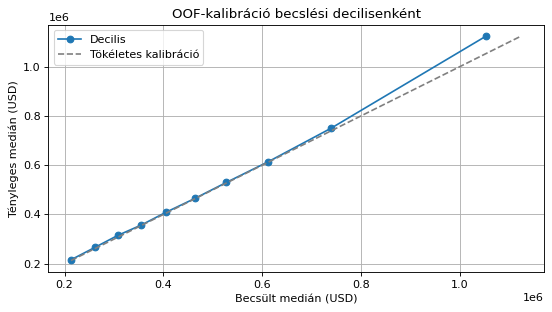

A decilis-összegarányok tartománya 0.938–0.989, az összesített arány 0.971. Ez lefelé torzítást jelez, ezért újrakalibrálást csak foldon belül próbálnék.


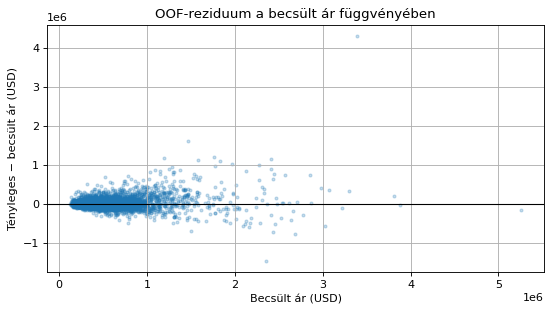

                          darab  MAE ($)  medián reziduum ($)
becsült_negyed                                               
(121421.819, 307602.43]   1,866   34,653                6,266
(307602.43, 433734.531]   1,865   41,999                3,653
(433734.531, 611455.812]  1,865   58,473                  779
(611455.812, 5261602.5]   1,866  128,812               11,247
A felső becslési negyed MAE-je $128,812, az alsóé $34,653; becslés–reziduum korreláció 0.166. A tölcsér miatt a drága szegmenst külön ellenőrizném.
Reziduum ár-sávonként (pozitív = alulbecslés):


,darab,medián_reziduum,WAPE
ár_sáv,,,
"[0.0, 250000.0)",902,"$-18,046",0.175
"[250000.0, 500000.0)",3571,"$1,916",0.111
"[500000.0, 1000000.0)",2496,"$19,401",0.108
"[1000000.0, 2000000.0)",426,"$163,152",0.167
"[2000000.0, inf)",67,"$424,061",0.212


Reziduum házkor szerint:


,darab,medián_reziduum,WAPE
kor_sáv,,,
"[-1.0, 20.0)",1959,"$6,009",0.112
"[20.0, 40.0)",1713,"$2,134",0.107
"[40.0, 60.0)",1612,"$3,450",0.132
"[60.0, 80.0)",1183,"$8,283",0.149
"[80.0, inf)",995,"$5,972",0.152


Reziduum a leggyakoribb irányítószámokban:


,darab,medián_reziduum,WAPE
zipcode,,,
98038,218,"$7,646",0.105
98023,210,"$-2,022",0.110
98034,199,"$2,340",0.121
98103,196,"$16,414",0.117
98133,188,"$-3,218",0.126
98115,186,"$24,436",0.129
98118,184,"$3,634",0.170
98052,183,"$3,301",0.098


A legnagyobb abszolút mediánhiba a(z) ár-sáv [2000000.0, inf) csoportban $424,061. Ezt célzottan mintáznám tovább, de új jellemzőt csak a fejlesztési foldokkal tartanék meg.


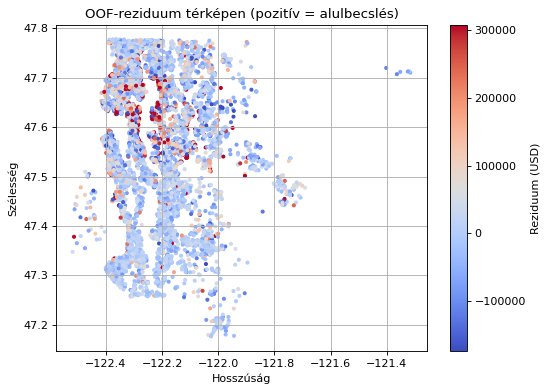

A legközelebbi, más ingatlanhoz tartozó reziduumok átlagával a korreláció 0.204. A térbeli együttmozgás foldon belüli helyi jellemző vizsgálatát indokolja.
Negatív vagy nem véges OOF-jóslat: 0; a becslések tartománya $121,422–$5,261,602.
Lehetetlen (negatív vagy nem véges) jóslatból 0 van. A pozitív tartományt az expm1 utáni alsó korlát biztosítja; a legdrágább jóslatokat külön mintáznám.


In [7]:
best_name = min(["Ridge", "Döntési fa", "Random Forest", "Boosting"], key=lambda n: base_results[n]["mean_wape"])
diag = base_results[best_name]["oof"].merge(
    cleaned[["price", "date", "zipcode", "lat", "long", "yr_built", "prop_id"]].reset_index(names="row"),
    on="row", validate="one_to_one", suffixes=("_oof", "_data"))
diag["residual"] = diag.actual-diag.predicted
diag["house_age"] = diag.date.dt.year-diag.yr_built
print(f"Legjobb alapmodell: {best_name}, foldátlag WAPE={base_results[best_name]['mean_wape']:.3f}.")
cal = diag.assign(decile=pd.qcut(diag.predicted, 10, duplicates="drop")).groupby("decile", observed=True).agg(
    darab=("actual", "size"), becsült_medián=("predicted", "median"), tényleges_medián=("actual", "median"),
    becsült_összeg=("predicted", "sum"), tényleges_összeg=("actual", "sum"))
cal["összegarány"] = cal.becsült_összeg/cal.tényleges_összeg
display(cal.style.format({"becsült_medián":"${:,.0f}", "tényleges_medián":"${:,.0f}",
                          "becsült_összeg":"${:,.0f}", "tényleges_összeg":"${:,.0f}", "összegarány":"{:.3f}"}))
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(cal.becsült_medián, cal.tényleges_medián, "o-", label="Decilis")
lo=min(cal.becsült_medián.min(),cal.tényleges_medián.min()); hi=max(cal.becsült_medián.max(),cal.tényleges_medián.max())
ax.plot([lo,hi],[lo,hi],"--",color="gray",label="Tökéletes kalibráció")
ax.set(title="OOF-kalibráció becslési decilisenként",xlabel="Becsült medián (USD)",ylabel="Tényleges medián (USD)"); ax.legend()
plt.tight_layout(); plt.show()
ratio=diag.predicted.sum()/diag.actual.sum()
direction="lefelé" if ratio<0.98 else "felfelé" if ratio>1.02 else "nem mutat érdemi irányú eltérést"
print(f"A decilis-összegarányok tartománya {cal.összegarány.min():.3f}–{cal.összegarány.max():.3f}, az összesített arány {ratio:.3f}. Ez {direction} torzítást jelez, ezért újrakalibrálást csak foldon belül próbálnék.")

fig, ax=plt.subplots(figsize=(7,4))
ax.scatter(diag.predicted,diag.residual,s=7,alpha=.25); ax.axhline(0,color="black",lw=1)
ax.set(title="OOF-reziduum a becsült ár függvényében",xlabel="Becsült ár (USD)",ylabel="Tényleges − becsült ár (USD)")
plt.tight_layout(); plt.show()
diag["becsült_negyed"]=pd.qcut(diag.predicted,4,duplicates="drop")
quart=diag.groupby("becsült_negyed",observed=True).apply(
    lambda g: pd.Series({"darab":len(g),"MAE ($)":g.residual.abs().mean(),"medián reziduum ($)":g.residual.median()}),
    include_groups=False)
print(quart.to_string(float_format=lambda x:f"{x:,.0f}"))
low,high=quart["MAE ($)"].iloc[0],quart["MAE ($)"].iloc[-1]
print(f"A felső becslési negyed MAE-je ${high:,.0f}, az alsóé ${low:,.0f}; becslés–reziduum korreláció {diag.predicted.corr(diag.residual):.3f}. {'A tölcsér miatt a drága szegmenst külön ellenőrizném.' if high>1.25*low else 'Erős tölcsér nem látszik, de a drága hibákat dollárban továbbra is figyelném.'}")

diag["ár_sáv"]=pd.cut(diag.actual,[0,250000,500000,1000000,2000000,np.inf],right=False)
diag["kor_sáv"]=pd.cut(diag.house_age,[-1,20,40,60,80,np.inf],right=False)
def segment(frame,key,minimum=1):
    out=frame.groupby(key,observed=True).agg(darab=("residual","size"),medián_reziduum=("residual","median"))
    out["WAPE"]=frame.groupby(key,observed=True).apply(lambda g:g.residual.abs().sum()/g.actual.sum(),include_groups=False)
    return out[out.darab>=minimum]
by_price=segment(diag,"ár_sáv"); by_age=segment(diag,"kor_sáv")
popular=diag.zipcode.value_counts().head(8).index
by_zip=segment(diag[diag.zipcode.isin(popular)],"zipcode",20).sort_values("darab",ascending=False)
print("Reziduum ár-sávonként (pozitív = alulbecslés):"); display(by_price.style.format({"medián_reziduum":"${:,.0f}","WAPE":"{:.3f}"}))
print("Reziduum házkor szerint:"); display(by_age.style.format({"medián_reziduum":"${:,.0f}","WAPE":"{:.3f}"}))
print("Reziduum a leggyakoribb irányítószámokban:"); display(by_zip.style.format({"medián_reziduum":"${:,.0f}","WAPE":"{:.3f}"}))
segments=[(abs(t.medián_reziduum),label,key,t.medián_reziduum) for label,table in [("ár-sáv",by_price),("házkor",by_age),("irányítószám",by_zip)] for key,t in table.iterrows()]
_,label,key,resid=max(segments)
print(f"A legnagyobb abszolút mediánhiba a(z) {label} {key} csoportban ${resid:,.0f}. Ezt célzottan mintáznám tovább, de új jellemzőt csak a fejlesztési foldokkal tartanék meg.")

fig,ax=plt.subplots(figsize=(7,5))
s=ax.scatter(diag.long,diag.lat,c=diag.residual,s=7,cmap="coolwarm",
             vmin=diag.residual.quantile(.02),vmax=diag.residual.quantile(.98))
ax.set(title="OOF-reziduum térképen (pozitív = alulbecslés)",xlabel="Hosszúság",ylabel="Szélesség")
fig.colorbar(s,ax=ax,label="Reziduum (USD)"); plt.tight_layout(); plt.show()
coords=np.c_[diag.lat.to_numpy(),diag.long.to_numpy()*np.cos(np.deg2rad(47.6))]
_,inds=cKDTree(coords).query(coords,k=min(8,len(diag))); inds=np.asarray(inds)
if inds.ndim==1: inds=inds[:,None]
neighbors=np.empty(len(diag)); props=diag.prop_id.to_numpy(); residuals=diag.residual.to_numpy()
for i,near in enumerate(inds):
    keep=near[props[near]!=props[i]][:5]; neighbors[i]=residuals[keep].mean() if len(keep) else np.nan
spatial_corr=np.corrcoef(residuals,neighbors)[0,1]
print(f"A legközelebbi, más ingatlanhoz tartozó reziduumok átlagával a korreláció {spatial_corr:.3f}. {'A térbeli együttmozgás foldon belüli helyi jellemző vizsgálatát indokolja.' if spatial_corr>.15 else 'A maradék térbeli korreláció gyenge, ezért földrajzi bővítést csak páros fold-összehasonlítással tartanék meg.'}")

bad=int((~np.isfinite(diag.predicted)).sum()+(diag.predicted<0).sum())
print(f"Negatív vagy nem véges OOF-jóslat: {bad}; a becslések tartománya ${diag.predicted.min():,.0f}–${diag.predicted.max():,.0f}.")
print(f"Lehetetlen (negatív vagy nem véges) jóslatból {bad} van. {'A visszaalakítást ellenőrizném.' if bad else 'A pozitív tartományt az expm1 utáni alsó korlát biztosítja; a legdrágább jóslatokat külön mintáznám.'}")


## 7. Visszacsatolási kör – célzott jellemzőcsoportok

A helyi árszint és a lakóterületi összetétel még magyarázhat szegmensenkénti hibát. Ezért egyenként és együtt összevetem a geo jellemzőket (Seattle/Bellevue távolságok, minimumuk, két 45°-os koordináta), az arányokat (lakó-/telekterület, fürdőszoba/hálószoba, alagsor, kor és felújítás), valamint a k=20 közeli eladás átlagos négyzetlábárát és annak lakóterülettel szorzott becslését.

A comps tanítósorainál kizárom a saját sort és minden azonos ingatlan kulcsú szomszédot; validációs eladásoknál csak az adott fold tanítójából keresek. A skálázás és one-hot kódolás minden foldon a `Pipeline`-ban tanul. A boosting és Random Forest minden konfigurációja három rögzített seed átlaga; valódi javulás csak akkor, ha mindhárom fold javulása pozitív, és az átlag nagyobb a foldok közötti szórásnál.


In [8]:
CONFIGS={"Alap":(),"Geo":("geo",),"Arányok":("arányok",),"Comps":("comps",),
         "Minden új jellemző":("geo","arányok","comps")}
SEEDS=(13,42,87)
families=["Ridge","Random Forest","Boosting"]
experiments={}
for model in families:
    seeds=(SEED,) if model=="Ridge" else SEEDS
    for config,groups in CONFIGS.items():
        if model in ["Random Forest", "Boosting"] and config == "Alap":
            remaining=cv(model,groups,(13,87),oof=True)
            first=base_results[model]
            paired=first["oof"].merge(remaining["oof"],on=["row","fold"],suffixes=("_one","_rest"))
            average_prediction=(paired.predicted_one+2*paired.predicted_rest)/3
            fold_scores=np.array([metrics(g.actual_one,(g.predicted_one+2*g.predicted_rest)/3)["WAPE"]
                                  for _,g in paired.groupby("fold")])
            experiments[(model,config)]={"fold_wapes":fold_scores,"mean_wape":float(fold_scores.mean()),
                "metrics":metrics(paired.actual_one,average_prediction)}
        else:
            experiments[(model,config)]=cv(model,groups,seeds)
        r=experiments[(model,config)]
        print(f"{model:14s} {config:20s} fold WAPE="+", ".join(f"{x:.3f}" for x in r["fold_wapes"])+f" | átlag {r['mean_wape']:.3f}")

rows=[]; proven=[]
for model in families:
    base=experiments[(model,"Alap")]["fold_wapes"]
    for config in list(CONFIGS)[1:]:
        improvement=base-experiments[(model,config)]["fold_wapes"]
        avg=float(improvement.mean()); sd=float(improvement.std(ddof=1))
        passed=bool(np.all(improvement>0) and avg>sd)
        rows.append({"Modell":model,"Jellemzőcsoport":config,"Fold 1 javulás":improvement[0],
                     "Fold 2 javulás":improvement[1],"Fold 3 javulás":improvement[2],
                     "Átlagos javulás":avg,"Foldok közti szórás":sd,"Bizonyított":passed})
        if passed: proven.append((model,config))
comparison=pd.DataFrame(rows)
display(comparison.style.format({c:"{:+.3f}" for c in ["Fold 1 javulás","Fold 2 javulás","Fold 3 javulás","Átlagos javulás"]}|{"Foldok közti szórás":"{:.3f}"}))
print(f"Bizonyított javulás: {proven if proven else 'nincs; egyik változat sem teljesíti a szabályt'}.")


Ridge          Alap                 fold WAPE=0.135, 0.138, 0.141 | átlag 0.138


Ridge          Geo                  fold WAPE=0.131, 0.137, 0.138 | átlag 0.135


Ridge          Arányok              fold WAPE=0.134, 0.138, 0.140 | átlag 0.137


Ridge          Comps                fold WAPE=0.122, 0.127, 0.128 | átlag 0.126


Ridge          Minden új jellemző   fold WAPE=0.120, 0.127, 0.127 | átlag 0.125


Random Forest  Alap                 fold WAPE=0.130, 0.134, 0.140 | átlag 0.135


... (7 outputs left out)

Boosting       Comps                fold WAPE=0.118, 0.118, 0.127 | átlag 0.121


Boosting       Minden új jellemző   fold WAPE=0.115, 0.116, 0.126 | átlag 0.119


,Modell,Jellemzőcsoport,Fold 1 javulás,Fold 2 javulás,Fold 3 javulás,Átlagos javulás,Foldok közti szórás,Bizonyított
0,Ridge,Geo,+0.003,+0.002,+0.003,+0.003,0.001,True
1,Ridge,Arányok,+0.001,+0.001,+0.001,+0.001,0.000,True
2,Ridge,Comps,+0.013,+0.011,+0.013,+0.012,0.001,True
3,Ridge,Minden új jellemző,+0.015,+0.011,+0.014,+0.013,0.002,True
4,Random Forest,Geo,+0.005,+0.005,+0.005,+0.005,0.000,True
5,Random Forest,Arányok,-0.000,-0.001,-0.001,-0.001,0.001,False
6,Random Forest,Comps,+0.005,+0.006,+0.007,+0.006,0.001,True
7,Random Forest,Minden új jellemző,+0.006,+0.007,+0.007,+0.007,0.000,True
8,Boosting,Geo,+0.002,+0.004,+0.001,+0.002,0.002,True
9,Boosting,Arányok,+0.002,+0.000,+0.000,+0.001,0.001,False


Bizonyított javulás: [('Ridge', 'Geo'), ('Ridge', 'Arányok'), ('Ridge', 'Comps'), ('Ridge', 'Minden új jellemző'), ('Random Forest', 'Geo'), ('Random Forest', 'Comps'), ('Random Forest', 'Minden új jellemző'), ('Boosting', 'Geo'), ('Boosting', 'Comps'), ('Boosting', 'Minden új jellemző')].


A páros különbség táblázat a foldonkénti WAPE-javulást mutatja (alap WAPE mínusz módosított WAPE). A minden új jellemzős lineáris modellt is mérem; a háromfoldos feltételt nem teljesítő változatot közlöm, de nem nevezem bizonyított nyereségnek.


## 8. Záró modellválasztás – kizárólag CV alapján

A jelöltek az alapmodellek az átlag és ZIP-medián nélkül, a minden új jellemzős lineáris modell, valamint a szigorú szabály szerint bizonyított változatok. A három fold átlagos WAPE-je választ; ezután a tesztingatlanok korábbi eladásai nélkül illesztem a teljes fejlesztési modellt, és a tesztet egyszer pontozom az átlagra, naiv ZIP-mediánra, alap lineárisra és a választott modellre. A 2 000 ismétléses ingatlan-klaszter bootstrap 95%-os intervallumot ad a kiválasztott modell RMSE/WAPE-jére és a naiv, illetve alap lineáris modellel vett páros különbségre; ez bizonytalansági leírás, nem hangolás.


In [9]:
candidates=[]
for model in ["Ridge","Döntési fa"]:
    r=base_results[model]
    candidates.append({"Modell":model,"Jellemzők":"Alap","kind":model,"groups":(),"wape":r["mean_wape"]})
for model in ["Random Forest","Boosting"]:
    r=experiments[(model,"Alap")]
    candidates.append({"Modell":model,"Jellemzők":"Alap (3 seed)","kind":model,"groups":(),"wape":r["mean_wape"]})
r=experiments[("Ridge","Minden új jellemző")]
candidates.append({"Modell":"Ridge","Jellemzők":"Minden új jellemző","kind":"Ridge","groups":CONFIGS["Minden új jellemző"],"wape":r["mean_wape"]})
for model,config in proven:
    candidates.append({"Modell":model,"Jellemzők":config,"kind":model,"groups":CONFIGS[config],"wape":experiments[(model,config)]["mean_wape"]})
candidates=pd.DataFrame(candidates).drop_duplicates(["Modell","Jellemzők"]).sort_values("wape")
display(candidates[["Modell","Jellemzők","wape"]].rename(columns={"wape":"Átlagos fold WAPE"}).style.format({"Átlagos fold WAPE":"{:.3f}"}))
choice=candidates.iloc[0]; kind=choice["kind"]; groups=choice["groups"]
seeds=SEEDS if kind in ["Random Forest","Boosting"] else (SEED,)
print(f"CV-választás: {kind}, {choice['Jellemzők']}; foldátlagos WAPE={choice.wape:.3f}.")

Xtrain,Xtest=make_features(final_train),make_features(test)
if "comps" in groups:
    Xtrain,Xtest=add_comps(Xtrain,Xtest,final_train,test,final_train.price.to_numpy())
cols=columns_for(groups); ytrain=final_train.price.to_numpy(); ytest=test.price.to_numpy()
preds={"Átlag":np.full(len(test),ytrain.mean())}
medians=final_train.groupby("zipcode").price.median()
preds["ZIP-medián"]=test.zipcode.map(medians).fillna(np.median(ytrain)).to_numpy()
preds["Ridge – alap"]=predict("Ridge",make_features(final_train)[columns_for(())],ytrain,
                              make_features(test)[columns_for(())],SEED)
seed_predictions=[predict(kind,Xtrain[cols],ytrain,Xtest[cols],seed) for seed in seeds]
preds["Kiválasztott"]=np.mean(seed_predictions,axis=0)
test_table=pd.DataFrame({name:metrics(ytest,p) for name,p in preds.items()}).T
display(test_table.style.format({"WAPE":"{:.3f}","RMSE":"${:,.0f}","MAE":"${:,.0f}",
                                 "RMSLE":"{:.3f}","R²":"{:.3f}","Jósolt/tényleges összeg":"{:.3f}"}))

rng=np.random.default_rng(20261108)
clusters=test.reset_index(drop=True).groupby("prop_id").indices
cluster_keys=np.array(list(clusters))
boot={n:{"RMSE":[],"WAPE":[]} for n in ["Kiválasztott","ZIP-medián","Ridge – alap"]}
for _ in range(2000):
    sample=np.concatenate([clusters[k] for k in rng.choice(cluster_keys,len(cluster_keys),replace=True)])
    for name in boot:
        score=metrics(ytest[sample],preds[name][sample])
        for measure in ["RMSE","WAPE"]: boot[name][measure].append(score[measure])
def ci(values): return np.quantile(values,[.025,.975])
rows=[{"Mennyiség":"Kiválasztott RMSE","Alsó 95%":ci(boot["Kiválasztott"]["RMSE"])[0],"Felső 95%":ci(boot["Kiválasztott"]["RMSE"])[1]},
      {"Mennyiség":"Kiválasztott WAPE","Alsó 95%":ci(boot["Kiválasztott"]["WAPE"])[0],"Felső 95%":ci(boot["Kiválasztott"]["WAPE"])[1]}]
for baseline in ["ZIP-medián","Ridge – alap"]:
    for measure in ["RMSE","WAPE"]:
        delta=np.asarray(boot["Kiválasztott"][measure])-np.asarray(boot[baseline][measure])
        rows.append({"Mennyiség":f"Kiválasztott − {baseline} ({measure})","Alsó 95%":ci(delta)[0],"Felső 95%":ci(delta)[1]})
boot_table=pd.DataFrame(rows).set_index("Mennyiség")
display(boot_table.style.format({c:lambda x:f"${x:,.0f}" if abs(x)>10 else f"{x:.3f}" for c in ["Alsó 95%","Felső 95%"]}))
print(f"A CV szerint választott modell foldátlagos WAPE-je {choice.wape:.3f}; a záró teszten {test_table.loc['Kiválasztott','WAPE']:.3f} (alap Ridge {test_table.loc['Ridge – alap','WAPE']:.3f}; ZIP-medián {test_table.loc['ZIP-medián','WAPE']:.3f}).")
print(f"A bootstrap {len(cluster_keys):,} tesztingatlan-klasztert mintáz 2 000 alkalommal; a kiválasztott teszt-WAPE 95%-os intervalluma {ci(boot['Kiválasztott']['WAPE'])[0]:.3f}–{ci(boot['Kiválasztott']['WAPE'])[1]:.3f}.")
print("A tesztet nem használtam a választásra, és a kapott metrikák alapján nem hangolok utólag.")


,Modell,Jellemzők,Átlagos fold WAPE
14,Boosting,Minden új jellemző,0.119
13,Boosting,Comps,0.121
12,Boosting,Geo,0.123
4,Ridge,Minden új jellemző,0.125
3,Boosting,Alap (3 seed),0.125
7,Ridge,Comps,0.126
11,Random Forest,Minden új jellemző,0.128
10,Random Forest,Comps,0.129
9,Random Forest,Geo,0.130
2,Random Forest,Alap (3 seed),0.135


CV-választás: Boosting, Minden új jellemző; foldátlagos WAPE=0.119.


,WAPE,RMSE,MAE,RMSLE,R²,Jósolt/tényleges összeg
Átlag,0.419,"$368,001","$232,376",0.532,-0.002,0.969
ZIP-medián,0.285,"$298,507","$157,876",0.366,0.341,0.856
Ridge – alap,0.144,"$137,067","$80,016",0.191,0.861,0.934
Kiválasztott,0.125,"$119,617","$69,489",0.172,0.894,0.939


,Alsó 95%,Felső 95%
Mennyiség,,
Kiválasztott RMSE,"$110,291","$129,612"
Kiválasztott WAPE,0.121,0.129
Kiválasztott − ZIP-medián (RMSE),"$-200,638","$-156,756"
Kiválasztott − ZIP-medián (WAPE),-0.168,-0.151
Kiválasztott − Ridge – alap (RMSE),"$-23,806","$-11,298"
Kiválasztott − Ridge – alap (WAPE),-0.023,-0.016


A CV szerint választott modell foldátlagos WAPE-je 0.119; a záró teszten 0.125 (alap Ridge 0.144; ZIP-medián 0.285).
A bootstrap 4,330 tesztingatlan-klasztert mintáz 2 000 alkalommal; a kiválasztott teszt-WAPE 95%-os intervalluma 0.121–0.129.
A tesztet nem használtam a választásra, és a kapott metrikák alapján nem hangolok utólag.


## 9. Korlátok

Az adat csak 13 hónapot fed le, ezért az időrendi teszt egyetlen szezonból áll, és nem igazolja a teljes éves vagy többéves általánosítást.
Az ingatlanazonosító a megadott hat mezőből képzett közelítés, így néhány azonos házhoz tartozó ismétlődő eladás rejtve maradhat.
A comps kizárólag földrajzi közelséget használ, ezért nem ragadja meg teljesen az állapot, minőség vagy piaci idő szerinti hasonlóságot.
